# 09 Spectrograms of the pulse and movement

Plan agreed with you on 2026-10-24: (1) a spectrogram encoder with our features on top, (2) small-data protection after that.

**What a spectrogram is here.** Every second, take the 10 s of signal around it and measure how strong each rhythm is, from 0 to 4 Hz in 64 steps of 0.0625 Hz. Stand these side by side through the night. The heartbeat shows as a bright band near 1 Hz, breathing as a band at about 0.2 to 0.4 Hz. Settings follow Tallal 2026; code in `src/spectro.py`, tests in `tests/test_spectro.py`.

**This notebook so far.** Section 1 looks at one person only, before building all 35.

In [1]:
import os
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from recording import Recording
from spectro import prepare_pulse, prepare_movement, spectrogram, epoch_spectrograms

DERIVED = ROOT / "data" / "derived"; FIGS = ROOT / "notebooks" / "figs"
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", ROOT / "data" / "raw"))
plt.rcParams.update({"font.size": 8})
df = pd.read_csv(DERIVED / "features_all35.csv")
people = sorted(df.subject.unique())
print("people:", len(people), "| epochs:", len(df))

people: 35 | epochs: 28189


## 1. One person, whole night

Person: the one with the most REM epochs, so REM is easy to find in the picture.

Numbers: missing values in the raw pulse and accelerometer, and how often the accelerometer really updates (the median number of value changes per second on ACC_X; a lower bound, since a new reading can equal the old one). Time to build one person, to estimate all 35.

Figure, three rows sharing the time axis (hours from the first scored epoch): the expert's sleep stages; the pulse spectrogram; the movement spectrogram. Brighter = stronger rhythm (natural log of power).

person: S015 | REM epochs: 190


missing values: BVP 0 | ACC 0 | samples 2373633
ACC_X value changes per second: median 6 | 90th percentile 22


built in 4s | per-second frames (37088, 64) | per epoch (955, 2, 30, 64)


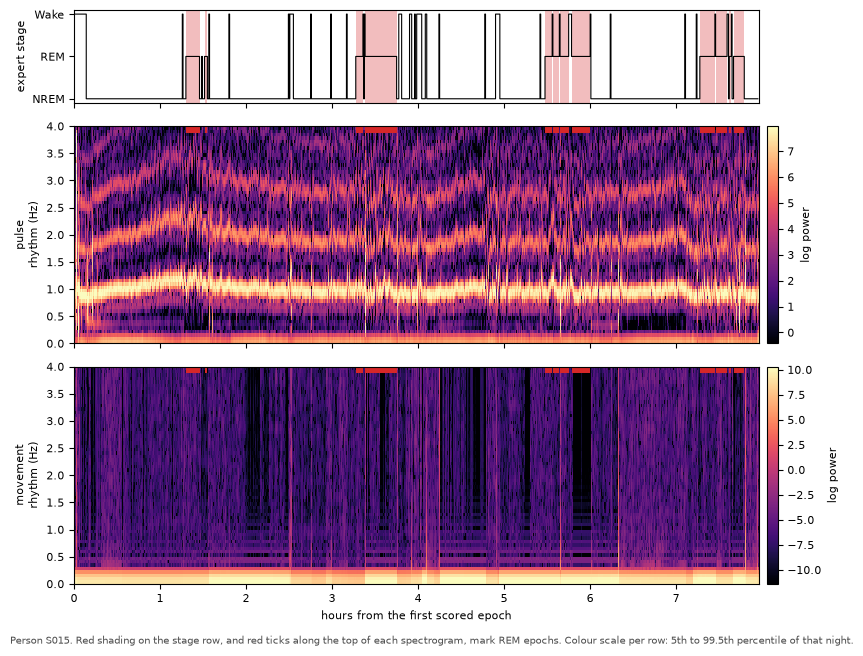

In [2]:
rem_n = df[df.stage3 == "REM"].groupby("subject").size()
s = rem_n.idxmax(); print("person:", s, "| REM epochs:", rem_n[s])
t0 = time.time()
rec = Recording.load(s, DATA_ROOT); w = rec.wrist
print("missing values: BVP", int(w.BVP.isna().sum()), "| ACC", int(w[["ACC_X", "ACC_Y", "ACC_Z"]].isna().sum().sum()),
      "| samples", len(w))
ax_ = w.ACC_X.to_numpy(); ch = np.r_[0, (np.diff(ax_) != 0)]
per_sec = ch[: ch.size // 64 * 64].reshape(-1, 64).sum(axis=1)
print("ACC_X value changes per second: median", int(np.median(per_sec)), "| 90th percentile", int(np.percentile(per_sec, 90)))

P = spectrogram(prepare_pulse(w.BVP.to_numpy()))
M = spectrogram(prepare_movement(w.ACC_X.to_numpy(), w.ACC_Y.to_numpy(), w.ACC_Z.to_numpy()))
ep = rec.epochs; k = ep.keep.to_numpy(bool); ss = ep.start_sample_wrist.to_numpy()[k]
E = epoch_spectrograms(P, M, ss)
print(f"built in {time.time() - t0:.0f}s | per-second frames {P.shape} | per epoch {E.shape}")

d = df[df.subject == s].sort_values("epoch")
assert len(d) == len(ss)
h0 = ss[0] / 64; hrs = (ss / 64 - h0) / 3600
fig, axs = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [0.6, 1.4, 1.4]})
lvl = d.stage3.map({"W": 2, "REM": 1, "NREM": 0}).to_numpy()
axs[0].step(hrs, lvl, where="post", color="k", lw=0.8)
for a, b in zip(hrs[lvl == 1], hrs[lvl == 1] + 0.5 / 60):
    axs[0].axvspan(a, b, color="tab:red", alpha=0.3, lw=0)
axs[0].set_yticks([0, 1, 2]); axs[0].set_yticklabels(["NREM", "REM", "Wake"]); axs[0].set_ylabel("expert stage")
sec0 = int(h0); n_sec = int((ss[-1] / 64 + 30) - h0)
for ax, S, name in [(axs[1], P, "pulse"), (axs[2], M, "movement")]:
    seg = S[sec0: sec0 + n_sec].T
    lo, hi = np.percentile(seg, [5, 99.5])
    im = ax.imshow(seg, aspect="auto", origin="lower", extent=[0, n_sec / 3600, 0, 4], cmap="magma", vmin=lo, vmax=hi,
                   interpolation="nearest")
    ax.set_ylabel(f"{name}\nrhythm (Hz)")
    for a, b in zip(hrs[lvl == 1], hrs[lvl == 1] + 0.5 / 60):
        ax.axvspan(a, b, ymin=0.97, ymax=1.0, color="tab:red", lw=0)
    cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("log power")
fig.colorbar(im, ax=axs[0], pad=0.01).ax.set_visible(False)
axs[2].set_xlabel("hours from the first scored epoch")
fig.text(0.01, 0.005, f"Person {s}. Red shading on the stage row, and red ticks along the top of each spectrogram, mark REM epochs. "
         "Colour scale per row: 5th to 99.5th percentile of that night.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.savefig(FIGS / "fig09_one_night.png", dpi=150); plt.show()

## 2. Build all 35, then the average spectrum per stage

Saved per person as `data/derived/spectro/<person>.npy` (half precision, shape epochs x 2 channels x 30 frames x 64 rhythms), rows in the same order as that person's rows in `features_all35.csv`. An existing file is loaded, not rebuilt.

**The average.** For each person and stage: the mean over that stage's epochs and their 30 frames, giving one value per rhythm. Then subtract that person's mean over the whole night, so each person is compared with their own night (people differ in overall signal strength). Then the median across the 29 people who had REM.

Numbers: for three rhythm bands, REM minus NREM (median across people) and how many of the 29 go the same way. Bands: breathing 0.15 to 0.5 Hz, heartbeat 0.7 to 1.7 Hz, harmonics 1.7 to 4 Hz.

Figure: left pulse, right movement. One line per stage, the median person; shading = middle half of people. Note: people have different heart rates, so the heartbeat band sits at different rhythms per person and the average blurs it.

built in 0s | files: 35 | total 216 MB
  signal                  band  REM minus NREM (median person)  people REM higher  people REM lower
   pulse breathing 0.15-0.5 Hz                          -0.333                 10                19
   pulse  heartbeat 0.7-1.7 Hz                          -0.251                 10                19
   pulse    harmonics 1.7-4 Hz                          -0.312                 10                19
movement breathing 0.15-0.5 Hz                           0.039                 15                14
movement  heartbeat 0.7-1.7 Hz                          -0.065                 14                15
movement    harmonics 1.7-4 Hz                          -0.075                 13                16


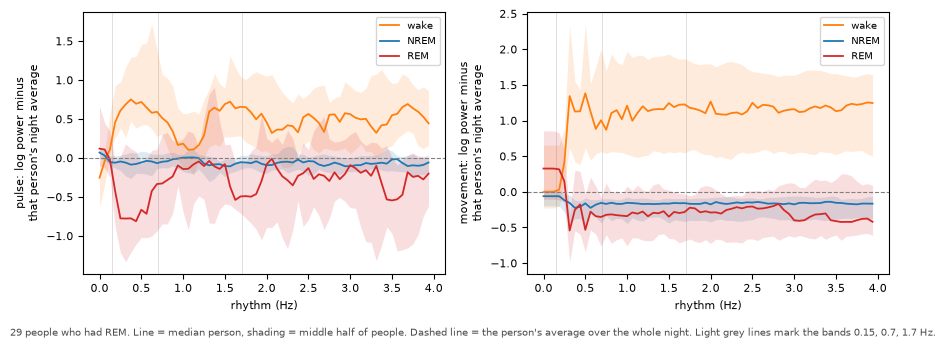

In [3]:
SPEC = DERIVED / "spectro"; SPEC.mkdir(exist_ok=True)
t0 = time.time()
for s in people:
    f = SPEC / f"{s}.npy"
    if f.exists():
        continue
    rec = Recording.load(s, DATA_ROOT); w = rec.wrist
    ep = rec.epochs; k = ep.keep.to_numpy(bool)
    d = df[df.subject == s]
    assert list(np.flatnonzero(k)) == list(d.sort_values("epoch").epoch), s
    P = spectrogram(prepare_pulse(w.BVP.to_numpy()))
    M = spectrogram(prepare_movement(w.ACC_X.to_numpy(), w.ACC_Y.to_numpy(), w.ACC_Z.to_numpy()))
    np.save(f, epoch_spectrograms(P, M, ep.start_sample_wrist.to_numpy()[k]).astype("float16"))
    del rec, w, P, M
print(f"built in {time.time() - t0:.0f}s | files: {len(list(SPEC.glob('*.npy')))} | "
      f"total {sum(f.stat().st_size for f in SPEC.glob('*.npy')) / 1e6:.0f} MB")

had_rem = df.groupby("subject").stage3.agg(lambda x: (x == "REM").any())
with_rem = list(had_rem[had_rem].index)
freqs = np.arange(64) * 32 / 512
prof = {st: [] for st in ["W", "NREM", "REM"]}
for s in with_rem:
    E = np.load(SPEC / f"{s}.npy").astype("float32").mean(axis=2)     # epochs x 2 x 64
    st = df[df.subject == s].sort_values("epoch").stage3.to_numpy()
    night = E.mean(axis=0)
    for k_ in prof:
        prof[k_].append(E[st == k_].mean(axis=0) - night if (st == k_).any() else np.full((2, 64), np.nan))
prof = {k_: np.array(v) for k_, v in prof.items()}                     # people x 2 x 64

bands = {"breathing 0.15-0.5 Hz": (0.15, 0.5), "heartbeat 0.7-1.7 Hz": (0.7, 1.7), "harmonics 1.7-4 Hz": (1.7, 4.0)}
rows = []
for ch, name in enumerate(["pulse", "movement"]):
    for b, (lo, hi) in bands.items():
        m = (freqs >= lo) & (freqs < hi)
        dlt = prof["REM"][:, ch, m].mean(axis=1) - prof["NREM"][:, ch, m].mean(axis=1)
        rows.append({"signal": name, "band": b, "REM minus NREM (median person)": np.median(dlt),
                     "people REM higher": int((dlt > 0).sum()), "people REM lower": int((dlt < 0).sum())})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
colors = {"W": "tab:orange", "NREM": "tab:blue", "REM": "tab:red"}
names = {"W": "wake", "NREM": "NREM", "REM": "REM"}
for ch, (ax, name) in enumerate(zip(axs, ["pulse", "movement"])):
    for st, c in colors.items():
        v = prof[st][:, ch]
        ax.plot(freqs, np.nanmedian(v, axis=0), color=c, lw=1.3, label=names[st])
        ax.fill_between(freqs, *np.nanpercentile(v, [25, 75], axis=0), color=c, alpha=0.15, lw=0)
    ax.axhline(0, color="0.5", ls="--", lw=0.8)
    for lo, hi in bands.values():
        ax.axvline(lo, color="0.85", lw=0.6, zorder=0)
    ax.set_xlabel("rhythm (Hz)"); ax.set_ylabel(f"{name}: log power minus\nthat person's night average")
    ax.legend(fontsize=7, loc="upper right")
fig.text(0.01, 0.005, "29 people who had REM. Line = median person, shading = middle half of people. Dashed line = the person's "
         "average over the whole night. Light grey lines mark the bands 0.15, 0.7, 1.7 Hz.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(FIGS / "fig09_stage_average.png", dpi=150); plt.show()

## 3. Does the spectrogram help each person?

Model: the balanced BiGRU from notebook 07, with a small spectrogram encoder added in front (`src/sequence.py`, `SpecEncoder`: three convolution blocks, about 23,000 weights). The encoder turns each epoch's picture (2 channels x 30 frames x 64 rhythms) into 64 numbers; these join the features before the BiGRU. Same 5 folds split by person, same training settings, one seed. HEAVY.

Runs:
- **features (reference):** the BiGRU with our 10 features + heart rate over minutes, from notebook 08 (`preds_bigru_balanced_plus_hrmin_5fold.csv`). No spectrogram.
- **spectrogram alone:** the encoder and BiGRU, no handcrafted features.
- **spectrogram + features:** the encoder plus the same 17 features as the reference.

Numbers: a table for all 35 and for the 29 with REM; paired per-person change on the 29.

Figure: each dot is one of the 29 people with REM; its height is how much that person's macro F1 changed in the comparison named below the column. Above the dashed line = better.

features: 17


  spec_only fold 0: best pass 30, validation macro F1 0.564, 358s


  spec_only fold 1: best pass 29, validation macro F1 0.491, 363s


  spec_only fold 2: best pass 29, validation macro F1 0.385, 354s


  spec_only fold 3: best pass 23, validation macro F1 0.488, 367s


  spec_only fold 4: best pass 28, validation macro F1 0.479, 369s


... (3 outputs left out)

  spec_plus_feat fold 3: best pass 29, validation macro F1 0.621, 612s


  spec_plus_feat fold 4: best pass 22, validation macro F1 0.503, 353s
                                    median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
people      run                                                                                         
all 35      features (reference)              0.475         0.310   0.244       0.335              0.167
            spectrogram alone                 0.451         0.247   0.256       0.542              0.354
            spectrogram + features            0.512         0.364   0.303       0.321              0.098
29 with REM features (reference)              0.477         0.290   0.260       0.335              0.171
            spectrogram alone                 0.451         0.191   0.267       0.542              0.377
            spectrogram + features            0.485         0.299   0.312       0.321              0.104



per person, 29 with REM:
  spectrogram alone minus features (reference): median -0.092  95% CI [-0.128, -0.012]  better 7 / worse 22


  spectrogram + features minus features (reference): median +0.013  95% CI [-0.040, +0.030]  better 16 / worse 13
  spectrogram + features minus spectrogram alone: median +0.077  95% CI [+0.020, +0.122]  better 24 / worse 5


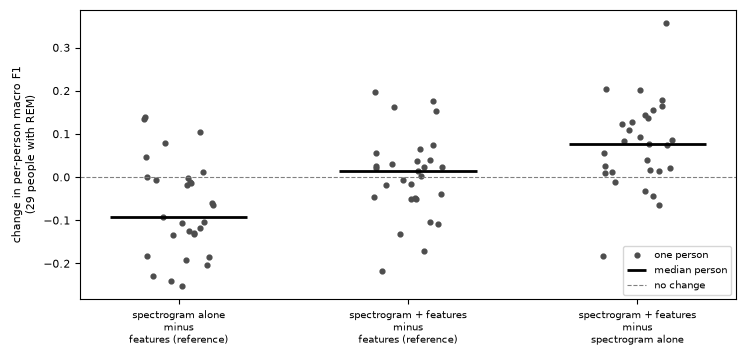

In [4]:
import warnings
from sklearn.metrics import cohen_kappa_score, f1_score
from splits import make_person_folds
from evaluation import make_xy, macro_f1_per_person, rem_rates
from metrics import paired_difference
from sequence import BiGRUSequence, make_sequences
from groups import build_group

folds = make_person_folds(people, n_folds=5, n_tune=4, seed=20261011)
hrmin = build_group("hrmin", None, True, people, None, df, DERIVED)          # loads the cached file
D = df.join(hrmin[[c for c in hrmin.columns if c.endswith("_z")]])
FEATS = [c for c in df.columns if c.endswith("_z")] + [c for c in hrmin.columns if c.endswith("_z")]
print("features:", len(FEATS))
SPECS = {s: np.load(SPEC / f"{s}.npy") for s in people}                   # float16, rows in epoch order
EPOCHS = {s: np.sort(df.loc[df.subject == s, "epoch"].to_numpy()) for s in people}

def run_spec(name, cols):
    X, y, s, idx = make_xy(D, cols)
    ep = D.loc[idx, "epoch"].to_numpy()
    parts = []
    for i, f in enumerate(folds):
        t0 = time.time()
        tr = np.isin(s, f["train"])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X[tr], axis=0) if X.shape[1] else np.zeros(0)
        seqs = make_sequences(X, y, s, idx, ep, np.where(np.isnan(med), 0.0, med))
        for q in seqs:
            pos = np.searchsorted(EPOCHS[q["subject"]], D.loc[q["row"], "epoch"].to_numpy())
            q["spec"] = SPECS[q["subject"]][pos]
        seq = {q["subject"]: q for q in seqs}
        m = BiGRUSequence(weighting="balanced").fit([seq[q] for q in f["train"]], [seq[q] for q in f["tune"]])
        test = [seq[q] for q in f["test"]]
        for q, yh in zip(test, m.predict(test)):
            parts.append(pd.DataFrame({"subject": q["subject"], "row": q["row"], "y": q["y"], "yhat": yh, "fold": i}))
        print(f"  {name} fold {i}: best pass {m.best_epoch_}, validation macro F1 {m.best_val_f1_:.3f}, {time.time() - t0:.0f}s")
    p = pd.concat(parts, ignore_index=True)
    p.to_csv(DERIVED / f"preds_bigru_{name}_5fold.csv", index=False)
    return p

def summary(p):
    t = macro_f1_per_person(p); rr, fr = rem_rates(p)
    return {"median_macro_f1": t.macro_f1.median(), "kappa_pooled": cohen_kappa_score(p.y, p.yhat),
            "rem_f1": f1_score(p.y, p.yhat, labels=[2], average="macro"), "rem_recall": rr, "false_rem_on_nrem": fr}

P = {"features (reference)": pd.read_csv(DERIVED / "preds_bigru_balanced_plus_hrmin_5fold.csv")}
P["spectrogram alone"] = run_spec("spec_only", [])
P["spectrogram + features"] = run_spec("spec_plus_feat", FEATS)

had_rem = df.groupby("subject").stage3.agg(lambda x: (x == "REM").any())
with_rem = list(had_rem[had_rem].index)
rows = []
for who, keep in [("all 35", people), ("29 with REM", with_rem)]:
    for label, p in P.items():
        rows.append({"people": who, "run": label, **summary(p[p.subject.isin(keep)])})
print(pd.DataFrame(rows).set_index(["people", "run"]).round(3).to_string())

F = {k: macro_f1_per_person(v[v.subject.isin(with_rem)]).macro_f1 for k, v in P.items()}
comps = [("spectrogram alone", "features (reference)"), ("spectrogram + features", "features (reference)"),
         ("spectrogram + features", "spectrogram alone")]
print("\nper person, 29 with REM:")
deltas = {}
for a, b in comps:
    d = paired_difference(F[a], F[b]); dl = (F[a] - F[b]).dropna(); deltas[(a, b)] = dl
    print(f"  {a} minus {b}: median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  "
          f"better {int((dl > 0).sum())} / worse {int((dl < 0).sum())}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, ((a, b), dl) in enumerate(deltas.items()):
    jit = np.random.default_rng(0).uniform(-0.15, 0.15, dl.size)
    ax.scatter(np.full(dl.size, i) + jit, dl, s=12, color="0.3", label="one person" if i == 0 else None)
    ax.hlines(dl.median(), i - 0.3, i + 0.3, color="k", lw=2, label="median person" if i == 0 else None)
ax.axhline(0, color="0.5", ls="--", lw=0.8, label="no change")
ax.set_xticks(range(len(deltas)))
ax.set_xticklabels([f"{a}\nminus\n{b}" for a, b in deltas], fontsize=7)
ax.set_ylabel("change in per-person macro F1\n(29 people with REM)")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "fig09_spectrogram_per_person.png", dpi=150); plt.show()